# Lab 4A: Audio Data Augmentation

Audio-specific data augmentation techniques for machine learning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import os
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


## 1. Load Audio

In [2]:
audio_path = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/XC710407-Warbler.mp3"  # CHANGE THIS

y_original, sr = librosa.load(audio_path, sr=None)
duration = len(y_original) / sr

print(f"Original audio:")
print(f"  Sample rate: {sr} Hz")
print(f"  Duration: {duration:.2f} seconds")
print(f"  Samples: {len(y_original):,}")

Original audio:
  Sample rate: 44100 Hz
  Duration: 4.76 seconds
  Samples: 209,761


## 2. Time Stretching

Change duration without changing pitch.

In [3]:
# Stretch rates
stretch_rates = [0.8, 1.0, 1.2]  # 0.8 = slower, 1.2 = faster

y_stretched = {}
for rate in stretch_rates:
    y_stretched[rate] = librosa.effects.time_stretch(y_original, rate=rate)
    print(f"Rate {rate}: {len(y_stretched[rate])} samples, {len(y_stretched[rate])/sr:.2f}s")

Rate 0.8: 262201 samples, 5.95s
Rate 1.0: 209761 samples, 4.76s
Rate 1.2: 174801 samples, 3.96s


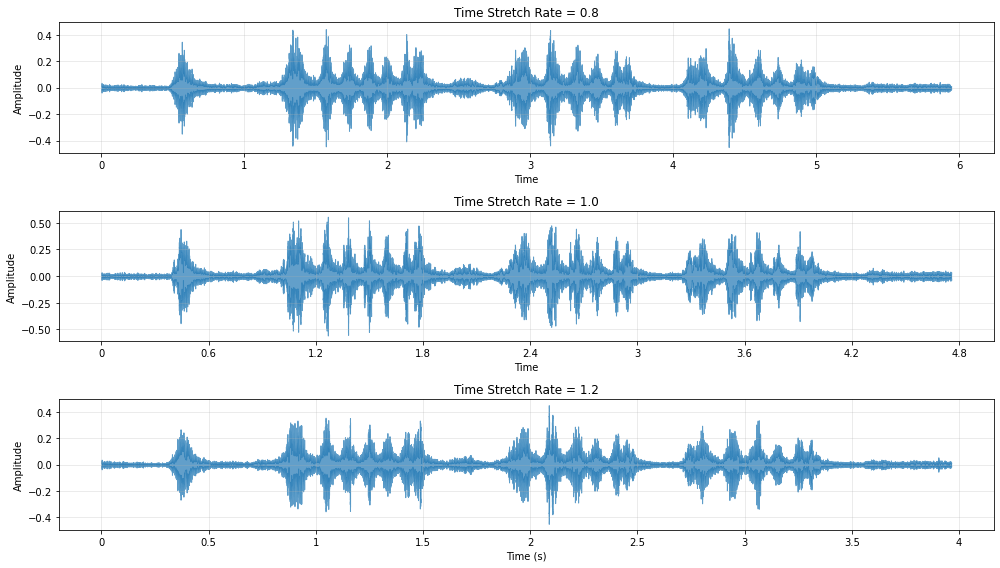

Saved: augmentation_time_stretch.png


In [4]:
# Visualize time stretching
fig, axes = plt.subplots(len(stretch_rates), 1, figsize=(14, 8))

for i, rate in enumerate(stretch_rates):
    librosa.display.waveshow(y_stretched[rate], sr=sr, ax=axes[i], alpha=0.7)
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(f'Time Stretch Rate = {rate}')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_time_stretch.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_time_stretch.png")

## 3. Pitch Shifting

Change pitch without changing duration.

In [5]:
# Pitch shifts in semitones
pitch_shifts = [-2, 0, 2]  # -2 = down 2 semitones, +2 = up 2 semitones

y_pitched = {}
for n_steps in pitch_shifts:
    y_pitched[n_steps] = librosa.effects.pitch_shift(y_original, sr=sr, n_steps=n_steps)
    print(f"Pitch shift {n_steps:+d} semitones: {len(y_pitched[n_steps])} samples")

Pitch shift -2 semitones: 209761 samples
Pitch shift +0 semitones: 209761 samples
Pitch shift +2 semitones: 209761 samples


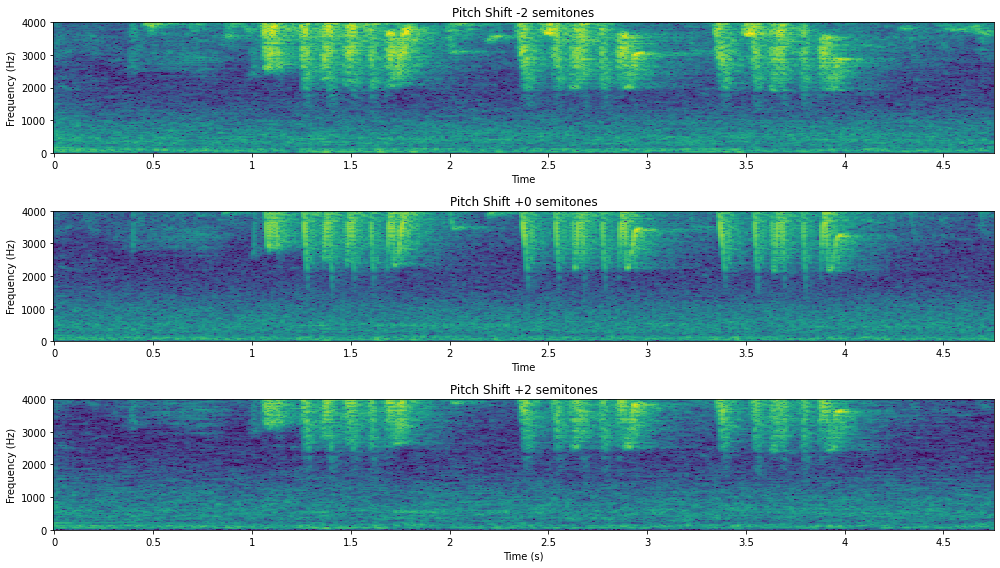

Saved: augmentation_pitch_shift.png


In [6]:
# Visualize pitch shifting (spectrograms)
fig, axes = plt.subplots(len(pitch_shifts), 1, figsize=(14, 8))

for i, n_steps in enumerate(pitch_shifts):
    D = librosa.stft(y_pitched[n_steps])
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    librosa.display.specshow(S_db, x_axis='time', y_axis='hz', sr=sr, ax=axes[i], cmap='viridis')
    axes[i].set_ylabel('Frequency (Hz)')
    axes[i].set_title(f'Pitch Shift {n_steps:+d} semitones')
    axes[i].set_ylim(0, 4000)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_pitch_shift.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_pitch_shift.png")

## 4. Adding Noise

Add white noise to audio.

In [7]:
def add_noise(audio, noise_factor=0.005):
    """Add white noise to audio."""
    noise = np.random.randn(len(audio))
    augmented = audio + noise_factor * noise
    return augmented

# Different noise levels
noise_factors = [0.002, 0.005, 0.01]

y_noisy = {}
for factor in noise_factors:
    y_noisy[factor] = add_noise(y_original, factor)
    snr = 10 * np.log10(np.mean(y_original**2) / np.mean((y_noisy[factor] - y_original)**2))
    print(f"Noise factor {factor}: SNR = {snr:.2f} dB")

Noise factor 0.002: SNR = 30.83 dB
Noise factor 0.005: SNR = 22.88 dB
Noise factor 0.01: SNR = 16.84 dB


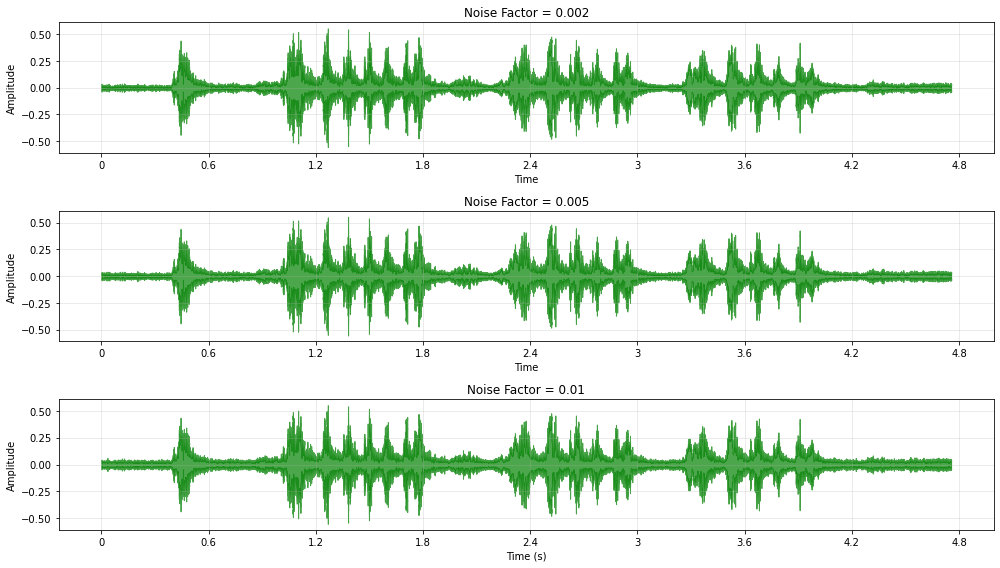

Saved: augmentation_noise.png


In [8]:
# Visualize noise addition
fig, axes = plt.subplots(len(noise_factors), 1, figsize=(14, 8))

for i, factor in enumerate(noise_factors):
    librosa.display.waveshow(y_noisy[factor], sr=sr, ax=axes[i], alpha=0.7, color='green')
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(f'Noise Factor = {factor}')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_noise.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_noise.png")

## 5. Time Shifting

Shift audio in time (circular shift).

In [9]:
def time_shift(audio, shift_max=0.2):
    """Shift audio in time."""
    shift = np.random.randint(int(sr * shift_max))
    return np.roll(audio, shift)

# Generate shifted versions
y_shifted_1 = time_shift(y_original, 0.1)
y_shifted_2 = time_shift(y_original, 0.2)
y_shifted_3 = time_shift(y_original, 0.3)

print("Generated 3 time-shifted versions")

Generated 3 time-shifted versions


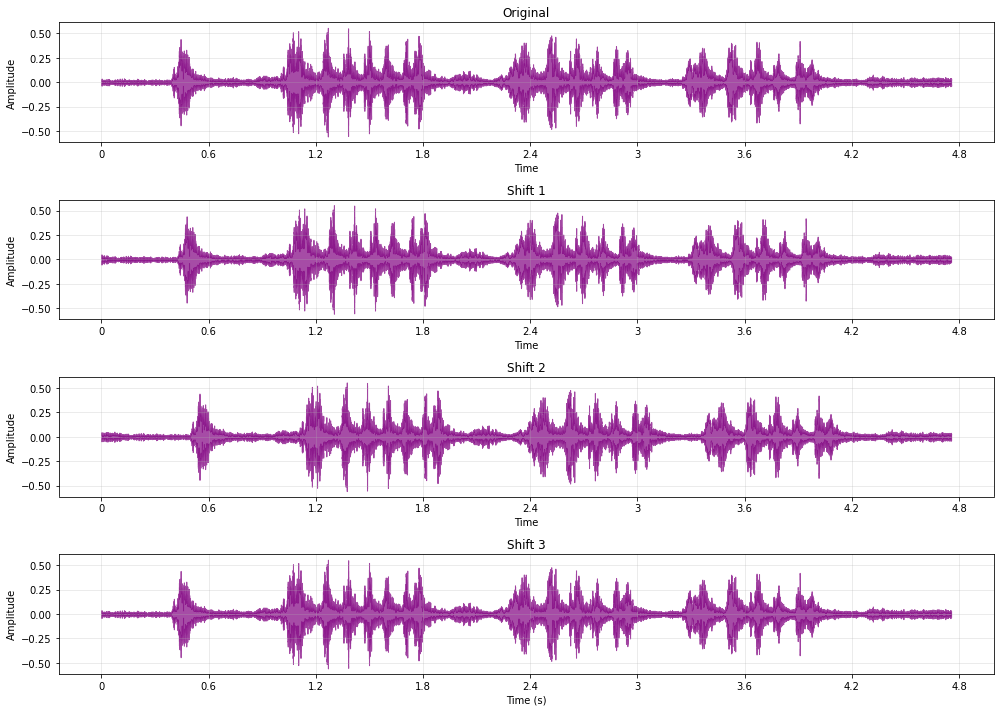

Saved: augmentation_time_shift.png


In [10]:
# Visualize time shifting
fig, axes = plt.subplots(4, 1, figsize=(14, 10))

shifted_versions = [
    (y_original, 'Original'),
    (y_shifted_1, 'Shift 1'),
    (y_shifted_2, 'Shift 2'),
    (y_shifted_3, 'Shift 3')
]

for i, (audio, label) in enumerate(shifted_versions):
    librosa.display.waveshow(audio, sr=sr, ax=axes[i], alpha=0.7, color='purple')
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(label)
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_time_shift.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_time_shift.png")

## 6. Volume/Gain Adjustment

In [11]:
def change_volume(audio, gain_db):
    """Change volume by gain in dB."""
    gain = 10 ** (gain_db / 20)
    return audio * gain

# Different gain levels
gains = [-6, 0, 6]  # dB

y_volume = {}
for gain_db in gains:
    y_volume[gain_db] = change_volume(y_original, gain_db)
    print(f"Gain {gain_db:+d} dB: max amplitude = {np.max(np.abs(y_volume[gain_db])):.4f}")

Gain -6 dB: max amplitude = 0.2785
Gain +0 dB: max amplitude = 0.5556
Gain +6 dB: max amplitude = 1.1086


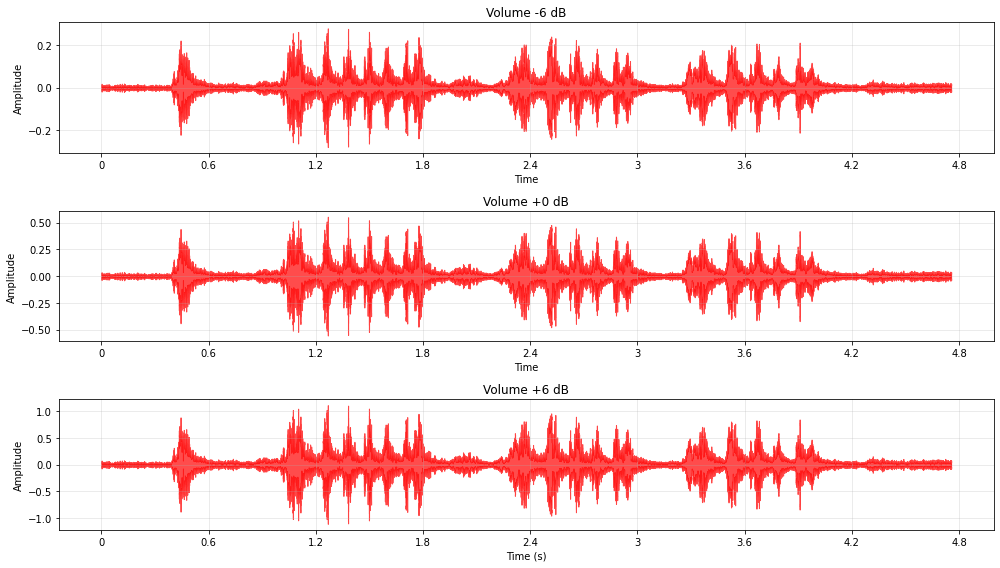

Saved: augmentation_volume.png


In [12]:
# Visualize volume changes
fig, axes = plt.subplots(len(gains), 1, figsize=(14, 8))

for i, gain_db in enumerate(gains):
    librosa.display.waveshow(y_volume[gain_db], sr=sr, ax=axes[i], alpha=0.7, color='red')
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(f'Volume {gain_db:+d} dB')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_volume.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_volume.png")

## 7. Polarity Inversion

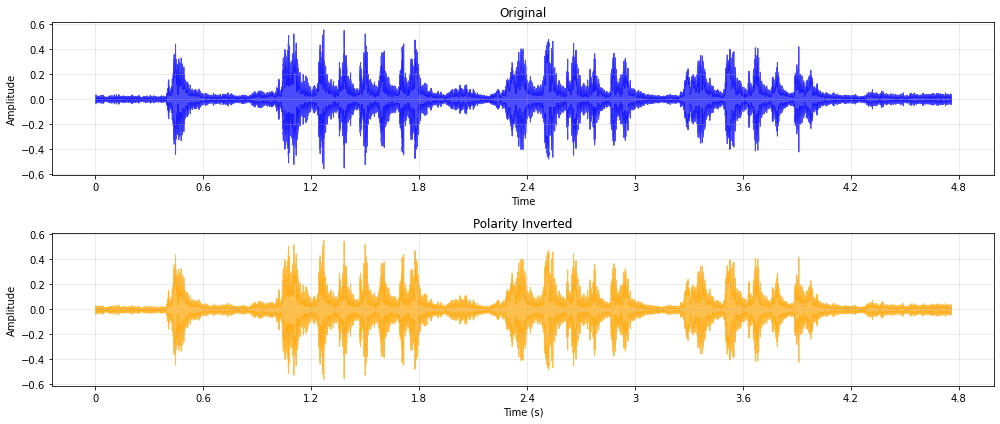

Saved: augmentation_polarity.png


In [13]:
# Invert polarity
y_inverted = -y_original

# Visualize polarity inversion
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

librosa.display.waveshow(y_original, sr=sr, ax=axes[0], alpha=0.7, color='blue')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Original')
axes[0].grid(True, alpha=0.3)

librosa.display.waveshow(y_inverted, sr=sr, ax=axes[1], alpha=0.7, color='orange')
axes[1].set_ylabel('Amplitude')
axes[1].set_xlabel('Time (s)')
axes[1].set_title('Polarity Inverted')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/augmentation_polarity.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_polarity.png")

## 8. Time Masking

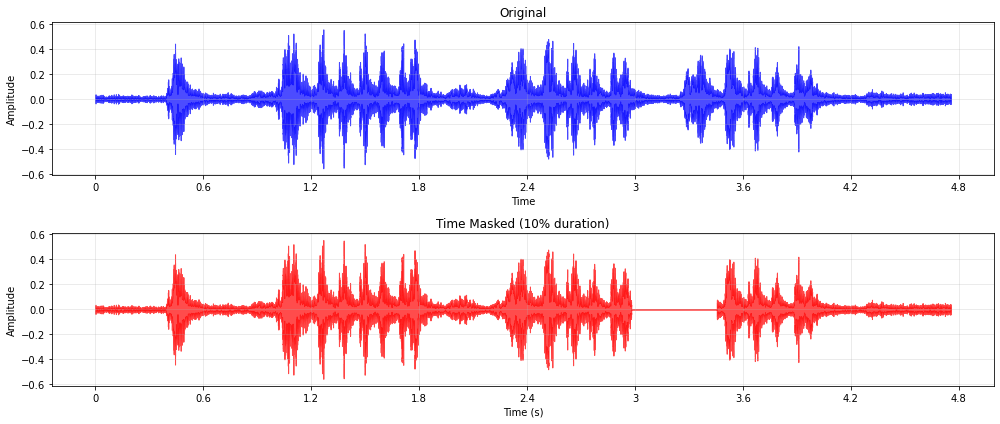

Saved: augmentation_time_mask.png


In [14]:
def time_mask(audio, mask_param=0.1):
    """Apply time masking (set random time segment to zero)."""
    audio_masked = audio.copy()
    mask_len = int(len(audio) * mask_param)
    mask_start = np.random.randint(0, len(audio) - mask_len)
    audio_masked[mask_start:mask_start + mask_len] = 0
    return audio_masked

# Generate masked versions
y_masked = time_mask(y_original, 0.1)

# Visualize
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

librosa.display.waveshow(y_original, sr=sr, ax=axes[0], alpha=0.7, color='blue')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Original')
axes[0].grid(True, alpha=0.3)

librosa.display.waveshow(y_masked, sr=sr, ax=axes[1], alpha=0.7, color='red')
axes[1].set_ylabel('Amplitude')
axes[1].set_xlabel('Time (s)')
axes[1].set_title('Time Masked (10% duration)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/augmentation_time_mask.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_time_mask.png")

## 9. Frequency Masking (SpecAugment)

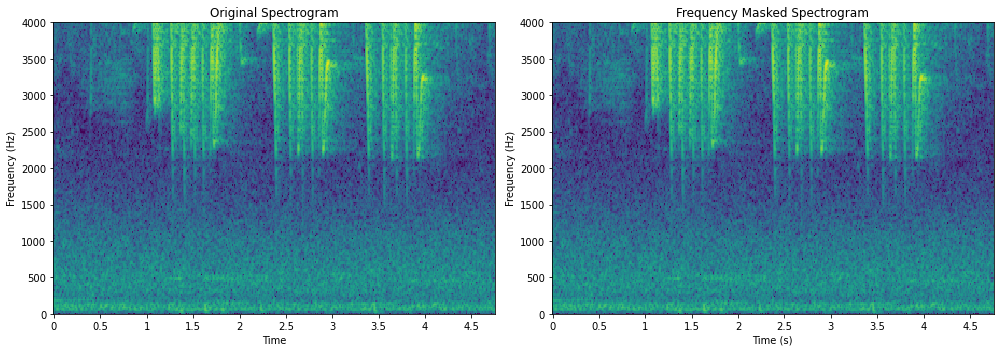

Saved: augmentation_frequency_mask.png


In [15]:
def frequency_mask(spectrogram, mask_param=10):
    """Apply frequency masking to spectrogram."""
    spec_masked = spectrogram.copy()
    num_freq_bins = spec_masked.shape[0]
    mask_start = np.random.randint(0, num_freq_bins - mask_param)
    spec_masked[mask_start:mask_start + mask_param, :] = 0
    return spec_masked

# Compute spectrogram
D = librosa.stft(y_original)
S = np.abs(D)
S_db = librosa.amplitude_to_db(S, ref=np.max)

# Apply frequency masking
S_masked = frequency_mask(S, mask_param=20)
S_masked_db = librosa.amplitude_to_db(S_masked, ref=np.max)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

librosa.display.specshow(S_db, x_axis='time', y_axis='hz', sr=sr, ax=axes[0], cmap='viridis')
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Original Spectrogram')
axes[0].set_ylim(0, 4000)

librosa.display.specshow(S_masked_db, x_axis='time', y_axis='hz', sr=sr, ax=axes[1], cmap='viridis')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Frequency Masked Spectrogram')
axes[1].set_ylim(0, 4000)

plt.tight_layout()
plt.savefig('results/augmentation_frequency_mask.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_frequency_mask.png")

## 10. Combine Multiple Augmentations

In [16]:
def augment_audio(audio, sr):
    """Apply random combination of augmentations."""
    # Random time stretch
    rate = np.random.uniform(0.8, 1.2)
    audio = librosa.effects.time_stretch(audio, rate=rate)
    
    # Random pitch shift
    n_steps = np.random.randint(-2, 3)
    audio = librosa.effects.pitch_shift(audio, sr=sr, n_steps=n_steps)
    
    # Random noise
    noise_factor = np.random.uniform(0.001, 0.005)
    audio = add_noise(audio, noise_factor)
    
    # Random volume
    gain_db = np.random.uniform(-3, 3)
    audio = change_volume(audio, gain_db)
    
    return audio

# Generate augmented versions
print("Generating augmented versions...")
augmented_versions = []
for i in range(5):
    aug = augment_audio(y_original, sr)
    augmented_versions.append(aug)
    print(f"  Version {i+1}: {len(aug)} samples")

print(f"\nGenerated {len(augmented_versions)} augmented versions")

Generating augmented versions...
  Version 1: 189337 samples
  Version 2: 188583 samples
  Version 3: 208925 samples
  Version 4: 194790 samples
  Version 5: 242124 samples

Generated 5 augmented versions


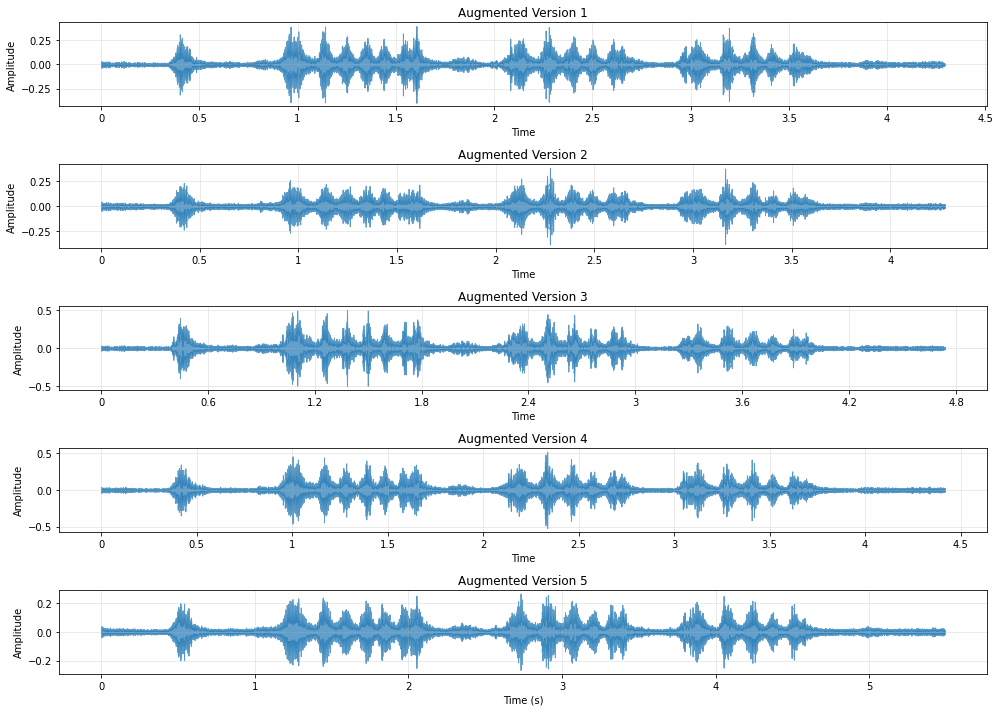

Saved: augmentation_combined.png


In [17]:
# Visualize augmented versions
fig, axes = plt.subplots(5, 1, figsize=(14, 10))

for i, aug in enumerate(augmented_versions):
    librosa.display.waveshow(aug, sr=sr, ax=axes[i], alpha=0.7)
    axes[i].set_ylabel('Amplitude')
    axes[i].set_title(f'Augmented Version {i+1}')
    axes[i].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('results/augmentation_combined.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved: augmentation_combined.png")

## 11. Save Augmented Audio Files

In [18]:
# Create output directory
output_dir = "augmented_audio"
os.makedirs(output_dir, exist_ok=True)

# Save original
sf.write(f"{output_dir}/original.wav", y_original, sr)

# Save time stretched
sf.write(f"{output_dir}/time_stretch_0.8.wav", y_stretched[0.8], sr)
sf.write(f"{output_dir}/time_stretch_1.2.wav", y_stretched[1.2], sr)

# Save pitch shifted
sf.write(f"{output_dir}/pitch_shift_-2.wav", y_pitched[-2], sr)
sf.write(f"{output_dir}/pitch_shift_+2.wav", y_pitched[2], sr)

# Save noisy
sf.write(f"{output_dir}/noisy_0.005.wav", y_noisy[0.005], sr)

# Save augmented versions
for i, aug in enumerate(augmented_versions):
    sf.write(f"{output_dir}/augmented_{i+1}.wav", aug, sr)

print(f"Saved {6 + len(augmented_versions)} audio files to {output_dir}/")
print(f"\nFiles saved:")
for file in sorted(os.listdir(output_dir)):
    print(f"  - {file}")

Saved 11 audio files to augmented_audio/

Files saved:
  - augmented_1.wav
  - augmented_2.wav
  - augmented_3.wav
  - augmented_4.wav
  - augmented_5.wav
  - noisy_0.005.wav
  - original.wav
  - pitch_shift_+2.wav
  - pitch_shift_-2.wav
  - time_stretch_0.8.wav
  - time_stretch_1.2.wav


## Summary

Audio augmentation techniques implemented:

1. **Time Stretching** - Change duration (0.8x, 1.2x)
2. **Pitch Shifting** - Change pitch (±2 semitones)
3. **Noise Addition** - Add white noise
4. **Time Shifting** - Circular shift in time
5. **Volume Adjustment** - Gain changes (±6 dB)
6. **Polarity Inversion** - Flip waveform
7. **Time Masking** - Zero out time segments
8. **Frequency Masking** - Zero out frequency bands
9. **Combined Augmentation** - Random combinations

**Output Files:**
- 9 PNG visualizations
- Multiple augmented WAV files in `augmented_audio/` directory

**Use Cases:**
- Increase training data size
- Improve model robustness
- Handle data scarcity
- Prevent overfitting